In [ ]:

import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


PyTorch: 2.11.0+cpu
OpenCV: 4.14.0
GPU available: False
Using: cpu


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/video_sr_project")
clean_dir = PROJECT_DIR / "data/clean"
raw_dir = PROJECT_DIR / "data/raw"

clean_dir.mkdir(parents=True, exist_ok=True)
raw_dir.mkdir(parents=True, exist_ok=True)

print("Project exists:", PROJECT_DIR.exists())
print("Raw video files:", list(raw_dir.glob("*")))
print("Clean frames:", len(list(clean_dir.glob("*.png"))))


Project exists: True
Raw video files: []
Clean frames: 0


In [7]:

from google.colab import files

uploaded = files.upload()

video_extensions = (".mp4", ".avi", ".mov", ".mkv")
video_names = [
    name for name in uploaded
    if name.lower().endswith(video_extensions)
]

if not video_names:
    raise ValueError("Upload a video file such as MP4.")

video_path = str(raw_dir / "source.mp4")

with open(video_path, "wb") as f:
    f.write(uploaded[video_names[0]])

print("Video saved:", video_path)


Saving 11940196-uhd_3840_2160_25fps.mp4 to 11940196-uhd_3840_2160_25fps.mp4
Video saved: /content/video_sr_project/data/raw/source.mp4


In [8]:

import cv2

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open the video. Try another MP4.")

total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

print("Video frames:", total)
print("Video FPS:", fps)

saved = 0
index = 0
target = min(100, total)
step = max(1, total // max(target, 1))

while saved < target:
    ret, frame = cap.read()
    if not ret:
        break

    if index % step == 0:
        frame = cv2.resize(
            frame, (640, 360),
            interpolation=cv2.INTER_AREA
        )
        output = clean_dir / f"frame_{saved:04d}.png"

        if cv2.imwrite(str(output), frame):
            saved += 1

    index += 1

cap.release()

print("Frames extracted:", saved)
print("Frames available:", len(list(clean_dir.glob("*.png"))))


Video frames: 363
Video FPS: 25.0
Frames extracted: 100
Frames available: 100


In [9]:
frames = sorted(clean_dir.glob("*.png"))

In [10]:

PROJECT_DIR = Path("/content/video_sr_project")
clean_dir = PROJECT_DIR / "data/clean"
checkpoint_dir = PROJECT_DIR / "checkpoints"
results_dir = PROJECT_DIR / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

frames = sorted(clean_dir.glob("*.png"))

print("Clean frames found:", len(frames))

if len(frames) < 20:
    raise ValueError(
        "Please extract at least 20 clean frames before continuing."
    )

sample = cv2.imread(str(frames[0]))
assert sample is not None

print("Frame dimensions (H, W, C):", sample.shape)


Clean frames found: 100
Frame dimensions (H, W, C): (360, 640, 3)


In [11]:

class ESPCN(nn.Module):
    def __init__(self, scale_factor=2):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, 5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, scale_factor**2, 3, padding=1)
        self.shuffle = nn.PixelShuffle(scale_factor)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.shuffle(self.conv3(x))

model = ESPCN(scale_factor=2).to(device)

test_input = torch.rand(1, 1, 180, 320, device=device)
with torch.no_grad():
    test_output = model(test_input)

assert test_output.shape == (1, 1, 360, 640)
print("ESPCN architecture test passed.")
print("Parameters:", sum(p.numel() for p in model.parameters()))


ESPCN architecture test passed.
Parameters: 21284


In [12]:

# Split the extracted frames
split = int(len(frames) * 0.8)
train_frames = frames[:split]
test_frames = frames[split:]

print("Training frames:", len(train_frames))
print("Testing frames:", len(test_frames))

def load_y_channel(path):
    image = cv2.imread(str(path))
    if image is None:
        return None

    ycrcb = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)
    return ycrcb[:, :, 0].astype(np.float32) / 255.0

train_images = [load_y_channel(p) for p in train_frames]
train_images = [im for im in train_images if im is not None]

print("Usable training images:", len(train_images))


Training frames: 80
Testing frames: 20
Usable training images: 80


In [13]:

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

epochs = 5
patch_size = 48
patches_per_image = 20

model.train()

for epoch in range(epochs):
    epoch_loss = 0.0
    patch_count = 0

    for hr in train_images:
        h, w = hr.shape

        if h < patch_size * 2 or w < patch_size * 2:
            continue

        for _ in range(patches_per_image):
            top = np.random.randint(0, h - patch_size * 2 + 1)
            left = np.random.randint(0, w - patch_size * 2 + 1)

            # HR target patch
            hr_patch = hr[
                top:top + patch_size * 2,
                left:left + patch_size * 2
            ]

            # Generate LR from the corresponding HR patch
            lr_patch = cv2.resize(
                hr_patch,
                (patch_size, patch_size),
                interpolation=cv2.INTER_CUBIC
            )

            lr_tensor = torch.from_numpy(lr_patch).float()[None, None].to(device)
            hr_tensor = torch.from_numpy(hr_patch).float()[None, None].to(device)

            optimizer.zero_grad()
            prediction = model(lr_tensor)
            loss = criterion(prediction, hr_tensor)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            patch_count += 1

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Mean MSE: {epoch_loss / max(patch_count, 1):.6f}"
    )

model.eval()

baseline_path = checkpoint_dir / "espcn_clean_baseline.pth"
torch.save(model.state_dict(), baseline_path)
print("Saved trained baseline:", baseline_path)


Epoch 1/5 | Mean MSE: 0.002828
Epoch 2/5 | Mean MSE: 0.000203
Epoch 3/5 | Mean MSE: 0.000278
Epoch 4/5 | Mean MSE: 0.000209
Epoch 5/5 | Mean MSE: 0.000214
Saved trained baseline: /content/video_sr_project/checkpoints/espcn_clean_baseline.pth


In [14]:

def evaluate_frame(path, jpeg_quality=30):
    hr = load_y_channel(path)

    if hr is None:
        return None

    h, w = hr.shape
    h = h - (h % 2)
    w = w - (w % 2)
    hr = hr[:h, :w]

    lr = cv2.resize(
        hr, (w // 2, h // 2),
        interpolation=cv2.INTER_CUBIC
    )

    # Simulate JPEG artifacts on the low-resolution input.
    lr_u8 = np.clip(lr * 255, 0, 255).astype(np.uint8)
    ok, encoded = cv2.imencode(
        ".jpg", lr_u8,
        [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality]
    )
    if not ok:
        raise RuntimeError("JPEG encoding failed")

    compressed_lr = cv2.imdecode(encoded, cv2.IMREAD_GRAYSCALE)
    compressed_lr = compressed_lr.astype(np.float32) / 255.0

    bicubic = cv2.resize(
        compressed_lr, (w, h),
        interpolation=cv2.INTER_CUBIC
    )

    x = torch.from_numpy(compressed_lr).float()[None, None].to(device)

    start = time.perf_counter()
    with torch.no_grad():
        pred = model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    sr = pred.squeeze().cpu().numpy()
    sr = np.clip(sr, 0, 1)

    bicubic = np.clip(bicubic, 0, 1)

    return {
        "hr": hr,
        "lr": compressed_lr,
        "bicubic": bicubic,
        "sr": sr,
        "latency_ms": elapsed * 1000,
        "psnr_bicubic": peak_signal_noise_ratio(
            hr, bicubic, data_range=1.0
        ),
        "psnr_espcn": peak_signal_noise_ratio(
            hr, sr, data_range=1.0
        ),
        "ssim_bicubic": structural_similarity(
            hr, bicubic, data_range=1.0
        ),
        "ssim_espcn": structural_similarity(
            hr, sr, data_range=1.0
        )
    }


In [15]:

results = []

for path in test_frames:
    result = evaluate_frame(path)
    if result is not None:
        results.append(result)

if not results:
    raise ValueError("No test frames were successfully evaluated.")

for key in [
    "psnr_bicubic", "psnr_espcn",
    "ssim_bicubic", "ssim_espcn", "latency_ms"
]:
    print(f"{key}: {np.mean([r[key] for r in results]):.4f}")


psnr_bicubic: 35.2454
psnr_espcn: 35.3319
ssim_bicubic: 0.9311
ssim_espcn: 0.9278
latency_ms: 96.1430


In [16]:

import pandas as pd

results_df = pd.DataFrame([
    {
        "PSNR_Bicubic": r["psnr_bicubic"],
        "PSNR_ESPCN": r["psnr_espcn"],
        "SSIM_Bicubic": r["ssim_bicubic"],
        "SSIM_ESPCN": r["ssim_espcn"],
        "ESPCN_Latency_ms": r["latency_ms"],
        "ESPCN_FPS_inference_only": 1000.0 / max(r["latency_ms"], 1e-9)
    }
    for r in results
])

csv_path = results_dir / "baseline_results.csv"
results_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)
display(results_df.head())


Saved: /content/video_sr_project/results/baseline_results.csv


,PSNR_Bicubic,PSNR_ESPCN,SSIM_Bicubic,SSIM_ESPCN,ESPCN_Latency_ms,ESPCN_FPS_inference_only
0,35.276357,35.330774,0.930708,0.927333,72.494185,13.794210
1,35.452062,35.533742,0.932665,0.929334,52.407516,19.081233
2,35.413120,35.482103,0.932699,0.929368,82.408818,12.134624
3,35.373580,35.440899,0.932443,0.929026,120.960804,8.267141
4,35.264315,35.351918,0.931280,0.927963,145.565016,6.869783


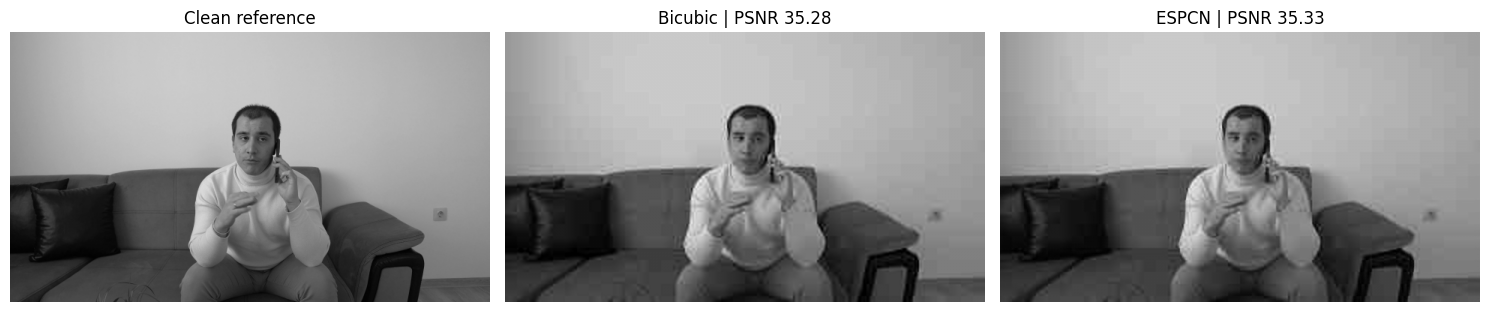

In [17]:

r = results[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(r["hr"], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Clean reference")

axes[1].imshow(r["bicubic"], cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Bicubic | PSNR {r['psnr_bicubic']:.2f}")

axes[2].imshow(r["sr"], cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"ESPCN | PSNR {r['psnr_espcn']:.2f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(results_dir / "baseline_comparison.png", dpi=150)
plt.show()


In [18]:

print("Number of test frames:", len(results))

print("\nAverage baseline metrics:")
print(results_df.mean(numeric_only=True).round(4))

print("\nSaved results:", csv_path)
print("Saved model:", baseline_path)


Number of test frames: 20

Average baseline metrics:
PSNR_Bicubic                35.2454
PSNR_ESPCN                  35.3319
SSIM_Bicubic                 0.9311
SSIM_ESPCN                   0.9278
ESPCN_Latency_ms            96.1430
ESPCN_FPS_inference_only    11.4687
dtype: float64

Saved results: /content/video_sr_project/results/baseline_results.csv
Saved model: /content/video_sr_project/checkpoints/espcn_clean_baseline.pth


In [19]:

# Use an already prepared test frame from the evaluation.
sample_lr = torch.from_numpy(
    results[0]["lr"]
).float()[None, None].to(device)

model.eval()

with torch.no_grad():
    for _ in range(30):
        _ = model(sample_lr)

    if device.type == "cuda":
        torch.cuda.synchronize()

    timings = []

    for _ in range(100):
        start = time.perf_counter()
        with torch.no_grad():
            _ = model(sample_lr)

        if device.type == "cuda":
            torch.cuda.synchronize()

        timings.append((time.perf_counter() - start) * 1000)

avg_ms = float(np.mean(timings))
fps = 1000.0 / avg_ms

print(f"Average inference latency: {avg_ms:.2f} ms")
print(f"Inference throughput: {fps:.2f} FPS")


Average inference latency: 61.51 ms
Inference throughput: 16.26 FPS


In [20]:

from google.colab import drive
import shutil

drive.mount("/content/drive")

backup_dir = Path(
    "/content/drive/MyDrive/Member1_ESPCN_Day1"
)
backup_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    str(baseline_path),
    str(backup_dir / "espcn_clean_baseline.pth")
)

shutil.copy2(
    str(csv_path),
    str(backup_dir / "baseline_results.csv")
)

shutil.copy2(
    str(results_dir / "baseline_comparison.png"),
    str(backup_dir / "baseline_comparison.png")
)

print("Checkpoint and evaluation results backed up to:", backup_dir)


Mounted at /content/drive
Checkpoint and evaluation results backed up to: /content/drive/MyDrive/Member1_ESPCN_Day1


In [21]:

from pathlib import Path
from google.colab import drive
import os

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/video_sr_project")
BACKUP_DIR = Path(
    "/content/drive/MyDrive/Member1_ESPCN_Day1"
)

print("=== Google Drive backup ===")
if BACKUP_DIR.exists():
    for item in sorted(BACKUP_DIR.iterdir()):
        print(item.name)
else:
    print("Backup folder not found.")

print("\n=== Current Colab session ===")
clean_dir = PROJECT_DIR / "data/clean"

if clean_dir.exists():
    clean_frames = sorted(clean_dir.glob("*.png"))
    print("Clean frames available:", len(clean_frames))
else:
    clean_frames = []
    print("Clean frame folder not found.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Google Drive backup ===
baseline_comparison.png
baseline_results.csv
espcn_clean_baseline.pth

=== Current Colab session ===
Clean frames available: 100


In [22]:

import cv2
import numpy as np

from pathlib import Path

PROJECT_DIR = Path("/content/video_sr_project")
CLEAN_DIR = PROJECT_DIR / "data/clean"
LR_DIR = PROJECT_DIR / "data/lr_degraded"
HR_DIR = PROJECT_DIR / "data/hr_targets"

LR_DIR.mkdir(parents=True, exist_ok=True)
HR_DIR.mkdir(parents=True, exist_ok=True)

clean_frames = sorted(CLEAN_DIR.glob("*.png"))

if not clean_frames:
    raise ValueError(
        "No clean frames found. Run Step 1 and restore or re-extract "
        "your video frames before continuing."
    )

quality = 30
scale = 2
saved = 0

for path in clean_frames:
    image = cv2.imread(str(path))

    if image is None:
        continue

    h, w = image.shape[:2]
    h -= h % scale
    w -= w % scale
    image = image[:h, :w]

    # Clean high-resolution target
    hr = image

    # Downscale to half width and height
    lr = cv2.resize(
        hr, (w // scale, h // scale),
        interpolation=cv2.INTER_CUBIC
    )

    # Introduce JPEG compression artifacts
    ok, encoded = cv2.imencode(
        ".jpg", lr,
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )

    if not ok:
        continue

    lr_compressed = cv2.imdecode(
        encoded, cv2.IMREAD_COLOR
    )

    cv2.imwrite(str(HR_DIR / path.name), hr)
    cv2.imwrite(str(LR_DIR / path.name), lr_compressed)
    saved += 1

print("Clean targets:", len(list(HR_DIR.glob("*.png"))))
print("Degraded inputs:", len(list(LR_DIR.glob("*.png"))))
print("JPEG quality:", quality)
print("Upscaling factor:", scale)


Clean targets: 100
Degraded inputs: 100
JPEG quality: 30
Upscaling factor: 2


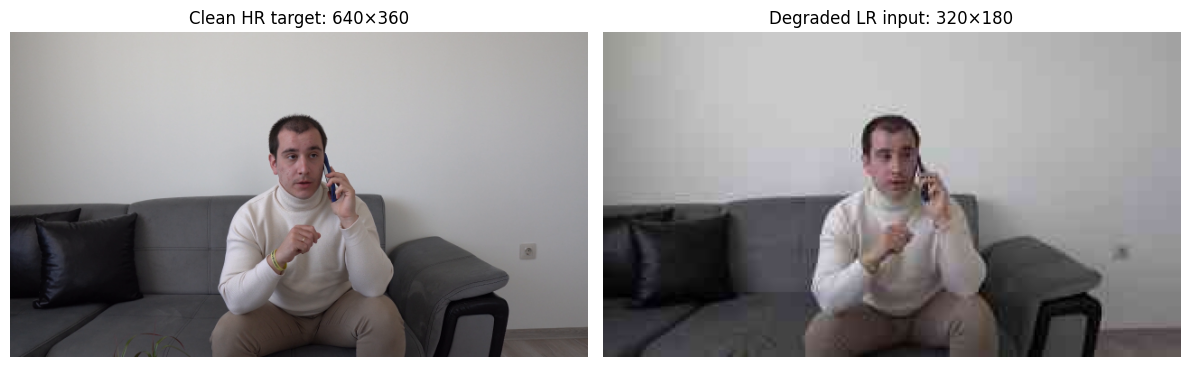

In [23]:

import matplotlib.pyplot as plt

hr_files = sorted(HR_DIR.glob("*.png"))

if not hr_files:
    raise ValueError("No paired training frames were generated.")

name = hr_files[0].name
hr = cv2.imread(str(HR_DIR / name))
lr = cv2.imread(str(LR_DIR / name))

hr_rgb = cv2.cvtColor(hr, cv2.COLOR_BGR2RGB)
lr_rgb = cv2.cvtColor(lr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(hr_rgb)
axes[0].set_title(f"Clean HR target: {hr.shape[1]}×{hr.shape[0]}")

axes[1].imshow(lr_rgb)
axes[1].set_title(f"Degraded LR input: {lr.shape[1]}×{lr.shape[0]}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [24]:

import shutil

DATASET_BACKUP = (
    Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
    / "degradation_dataset"
)

DATASET_BACKUP.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    str(LR_DIR),
    str(DATASET_BACKUP / "lr_degraded"),
    dirs_exist_ok=True
)

shutil.copytree(
    str(HR_DIR),
    str(DATASET_BACKUP / "hr_targets"),
    dirs_exist_ok=True
)

print("Dataset saved to:", DATASET_BACKUP)
print("LR pairs:", len(list(
    (DATASET_BACKUP / "lr_degraded").glob("*.png")
)))
print("HR pairs:", len(list(
    (DATASET_BACKUP / "hr_targets").glob("*.png")
)))


Dataset saved to: /content/drive/MyDrive/Member1_ESPCN_Day1/degradation_dataset
LR pairs: 100
HR pairs: 100


In [25]:

from pathlib import Path
import cv2

base = Path(
    "/content/drive/MyDrive/Member1_ESPCN_Day1/degradation_dataset"
)

lr_dir = base / "lr_degraded"
hr_dir = base / "hr_targets"

lr_files = sorted(lr_dir.glob("*.png"))
hr_files = sorted(hr_dir.glob("*.png"))

print("Degraded inputs:", len(lr_files))
print("Clean targets:", len(hr_files))

assert len(lr_files) > 0, "No degraded inputs found."
assert len(lr_files) == len(hr_files), "Pair counts do not match."

for lr_path in lr_files[:5]:
    hr_path = hr_dir / lr_path.name
    assert hr_path.exists(), f"Missing target: {lr_path.name}"

    lr = cv2.imread(str(lr_path))
    hr = cv2.imread(str(hr_path))

    assert lr is not None and hr is not None

    print(
        lr_path.name,
        "| LR:", lr.shape,
        "| HR:", hr.shape
    )

    assert hr.shape[0] == lr.shape[0] * 2
    assert hr.shape[1] == lr.shape[1] * 2

print("Dataset pairing and dimensions verified!")


Degraded inputs: 100
Clean targets: 100
frame_0000.png | LR: (180, 320, 3) | HR: (360, 640, 3)
frame_0001.png | LR: (180, 320, 3) | HR: (360, 640, 3)
frame_0002.png | LR: (180, 320, 3) | HR: (360, 640, 3)
frame_0003.png | LR: (180, 320, 3) | HR: (360, 640, 3)
frame_0004.png | LR: (180, 320, 3) | HR: (360, 640, 3)
Dataset pairing and dimensions verified!


In [26]:

from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import time

from skimage.metrics import peak_signal_noise_ratio, structural_similarity

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
DATA = BASE / "degradation_dataset"
LR_DIR = DATA / "lr_degraded"
HR_DIR = DATA / "hr_targets"

BASELINE_PATH = BASE / "espcn_clean_baseline.pth"
RETRAINED_PATH = BASE / "espcn_codec_adapted.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Re-create the same split based on the original clean frames.
CLEAN_DIR = Path("/content/video_sr_project/data/clean")
clean_files = sorted(CLEAN_DIR.glob("*.png"))

if len(clean_files) < 20:
    raise ValueError(
        "Clean frames are missing from the current Colab session. "
        "Re-extract the original video frames before continuing."
    )

split = int(len(clean_files) * 0.8)
train_names = {p.name for p in clean_files[:split]}
test_names = {p.name for p in clean_files[split:]}

train_names &= {p.name for p in LR_DIR.glob("*.png")}
test_names &= {p.name for p in LR_DIR.glob("*.png")}

print("Training pairs:", len(train_names))
print("Held-out test pairs:", len(test_names))
print("Baseline exists:", BASELINE_PATH.exists())

assert len(train_names) > 0 and len(test_names) > 0
assert BASELINE_PATH.exists()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu
Training pairs: 80
Held-out test pairs: 20
Baseline exists: True


In [27]:

class ESPCN(nn.Module):
    def __init__(self, scale_factor=2):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, 5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, scale_factor**2, 3, padding=1)
        self.shuffle = nn.PixelShuffle(scale_factor)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.shuffle(self.conv3(x))


baseline = ESPCN(scale_factor=2).to(device)
state = torch.load(
    BASELINE_PATH, map_location=device, weights_only=True
)
baseline.load_state_dict(state)
baseline.eval()

print("Baseline checkpoint loaded successfully.")


Baseline checkpoint loaded successfully.


In [28]:

import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

model = ESPCN(scale_factor=2).to(device)
model.load_state_dict(baseline.state_dict())

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

PATCH = 48
PATCHES_PER_FRAME = 10
EPOCHS = 5

def read_y(path):
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"Cannot read image: {path}")
    y = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)[:, :, 0]
    return y.astype(np.float32) / 255.0

model.train()

for epoch in range(EPOCHS):
    total_loss = 0.0
    count = 0

    names = sorted(train_names)
    random.shuffle(names)

    for name in names:
        lr = read_y(LR_DIR / name)
        hr = read_y(HR_DIR / name)

        if hr.shape != (lr.shape[0] * 2, lr.shape[1] * 2):
            raise ValueError(f"Unexpected dimensions for {name}")

        h, w = lr.shape
        if h < PATCH or w < PATCH:
            continue

        for _ in range(PATCHES_PER_FRAME):
            top = random.randint(0, h - PATCH)
            left = random.randint(0, w - PATCH)

            lr_patch = lr[top:top+PATCH, left:left+PATCH]
            hr_patch = hr[
                top*2:(top+PATCH)*2,
                left*2:(left+PATCH)*2
            ]

            x = torch.from_numpy(lr_patch.copy()).float()
            x = x[None, None].to(device)

            y = torch.from_numpy(hr_patch.copy()).float()
            y = y[None, None].to(device)

            optimizer.zero_grad()
            pred = model(x)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            count += 1

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Mean MSE: {total_loss / max(count, 1):.6f}"
    )

model.eval()

torch.save(model.state_dict(), RETRAINED_PATH)
print("Saved retrained model:", RETRAINED_PATH)


Epoch 1/5 | Mean MSE: 0.000337
Epoch 2/5 | Mean MSE: 0.000316
Epoch 3/5 | Mean MSE: 0.000303
Epoch 4/5 | Mean MSE: 0.000284
Epoch 5/5 | Mean MSE: 0.000284
Saved retrained model: /content/drive/MyDrive/Member1_ESPCN_Day1/espcn_codec_adapted.pth


In [29]:

def evaluate_model(net, names):
    psnr_values = []
    ssim_values = []

    net.eval()

    with torch.no_grad():
        for name in sorted(names):
            lr = read_y(LR_DIR / name)
            hr = read_y(HR_DIR / name)

            x = torch.from_numpy(lr).float()[None, None].to(device)
            pred = net(x).squeeze().cpu().numpy()
            pred = np.clip(pred, 0.0, 1.0)

            psnr_values.append(
                peak_signal_noise_ratio(hr, pred, data_range=1.0)
            )
            ssim_values.append(
                structural_similarity(hr, pred, data_range=1.0)
            )

    return {
        "PSNR_dB": float(np.mean(psnr_values)),
        "SSIM": float(np.mean(ssim_values)),
        "frames": len(psnr_values)
    }


baseline_metrics = evaluate_model(baseline, test_names)
retrained_metrics = evaluate_model(model, test_names)

print("Baseline:", baseline_metrics)
print("Retrained:", retrained_metrics)
print(
    "PSNR change (dB):",
    round(
        retrained_metrics["PSNR_dB"] - baseline_metrics["PSNR_dB"],
        4
    )
)
print(
    "SSIM change:",
    round(
        retrained_metrics["SSIM"] - baseline_metrics["SSIM"],
        4
    )
)


Baseline: {'PSNR_dB': 35.41994820359057, 'SSIM': 0.9276234097190488, 'frames': 20}
Retrained: {'PSNR_dB': 36.71584052019451, 'SSIM': 0.950788032418731, 'frames': 20}
PSNR change (dB): 1.2959
SSIM change: 0.0232


In [30]:

import pandas as pd

comparison = pd.DataFrame([
    {"Model": "Clean-trained baseline", **baseline_metrics},
    {"Model": "JPEG-adapted ESPCN", **retrained_metrics}
])

report_path = BASE / "codec_retraining_comparison.csv"
comparison.to_csv(report_path, index=False)

display(comparison)
print("Comparison saved to:", report_path)


,Model,PSNR_dB,SSIM,frames
0,Clean-trained baseline,35.419948,0.927623,20
1,JPEG-adapted ESPCN,36.715841,0.950788,20


Comparison saved to: /content/drive/MyDrive/Member1_ESPCN_Day1/codec_retraining_comparison.csv


In [31]:

import subprocess
import shutil

if shutil.which("ffmpeg") is None:
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "ffmpeg"],
        check=True
    )

result = subprocess.run(
    ["ffmpeg", "-version"],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout.splitlines()[0])


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


In [32]:

from pathlib import Path
import cv2
import subprocess
import shutil

PROJECT_DIR = Path("/content/video_sr_project")
CLEAN_DIR = PROJECT_DIR / "data/clean"
WORK_DIR = PROJECT_DIR / "h264_work"

LR_DIR = PROJECT_DIR / "data/lr_h264"
HR_DIR = PROJECT_DIR / "data/hr_targets_h264"

for folder in [WORK_DIR, LR_DIR, HR_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

clean_files = sorted(CLEAN_DIR.glob("*.png"))

if len(clean_files) < 20:
    raise ValueError(
        "Clean frames are missing. Re-extract your video frames first."
    )

# Use a consistent sequence of clean reference frames.
# Keep the original clean frames unchanged.
sequence_dir = WORK_DIR / "lr_sequence"
sequence_dir.mkdir(parents=True, exist_ok=True)

valid_names = []

for path in clean_files:
    image = cv2.imread(str(path))
    if image is None:
        continue

    h, w = image.shape[:2]
    h -= h % 2
    w -= w % 2
    image = image[:h, :w]

    lr = cv2.resize(
        image,
        (w // 2, h // 2),
        interpolation=cv2.INTER_CUBIC
    )

    name = f"frame_{len(valid_names):05d}.png"

    if not cv2.imwrite(str(sequence_dir / name), lr):
        continue

    # Save the matching clean target.
    cv2.imwrite(str(HR_DIR / name), image)
    valid_names.append(name)

if not valid_names:
    raise ValueError("No valid frames were available.")

video_path = WORK_DIR / "compressed_h264.mp4"

cmd = [
    "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
    "-framerate", "25",
    "-i", str(sequence_dir / "frame_%05d.png"),
    "-frames:v", str(len(valid_names)),
    "-c:v", "libx264",
    "-preset", "medium",
    "-crf", "36",
    "-pix_fmt", "yuv420p",
    str(video_path)
]

subprocess.run(cmd, check=True)
print("H.264 video created:", video_path)
print("Reference frames:", len(valid_names))


H.264 video created: /content/video_sr_project/h264_work/compressed_h264.mp4
Reference frames: 100


In [33]:

decoded_dir = WORK_DIR / "decoded"
decoded_dir.mkdir(parents=True, exist_ok=True)

subprocess.run([
    "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
    "-i", str(video_path),
    "-vsync", "0",
    "-start_number", "0",
    str(decoded_dir / "frame_%05d.png")
], check=True)

decoded_files = sorted(decoded_dir.glob("*.png"))

if len(decoded_files) != len(valid_names):
    raise ValueError(
        f"Frame count mismatch: {len(decoded_files)} decoded, "
        f"{len(valid_names)} reference frames. "
        "Do not use these pairs until alignment is checked."
    )

for i, path in enumerate(decoded_files):
    destination = LR_DIR / valid_names[i]
    shutil.copy2(path, destination)

print("H.264-degraded inputs:", len(list(LR_DIR.glob("*.png"))))
print("Clean targets:", len(list(HR_DIR.glob("*.png"))))
print("Frame pairing check passed.")


H.264-degraded inputs: 100
Clean targets: 100
Frame pairing check passed.


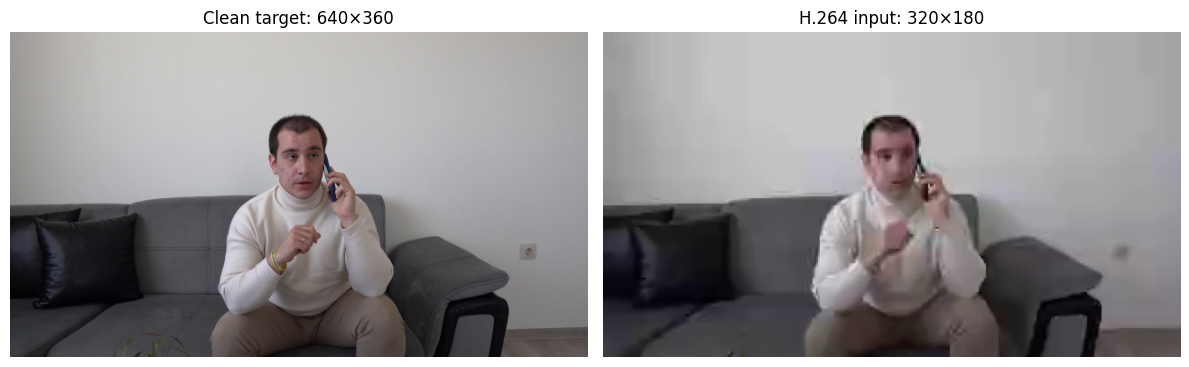

H.264 frame inspection passed.


In [34]:

import matplotlib.pyplot as plt

name = valid_names[0]

hr = cv2.imread(str(HR_DIR / name))
lr = cv2.imread(str(LR_DIR / name))

assert hr is not None and lr is not None
assert hr.shape[0] == lr.shape[0] * 2
assert hr.shape[1] == lr.shape[1] * 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cv2.cvtColor(hr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Clean target: {hr.shape[1]}×{hr.shape[0]}")

axes[1].imshow(cv2.cvtColor(lr, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"H.264 input: {lr.shape[1]}×{lr.shape[0]}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("H.264 frame inspection passed.")


In [37]:

from pathlib import Path
import shutil

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
BACKUP = BASE / "h264_dataset"

# Check H.264 dataset files
lr_files = list((BACKUP / "lr_h264").glob("*.png"))
hr_files = list((BACKUP / "hr_targets_h264").glob("*.png"))

print("H.264 degraded inputs:", len(lr_files))
print("Clean targets:", len(hr_files))

# Check retrained checkpoint
checkpoint = BASE / "espcn_codec_adapted.pth"
print("Retrained checkpoint exists:", checkpoint.exists())

# Verify matching filenames
lr_names = {p.name for p in (BACKUP / "lr_h264").glob("*.png")}
hr_names = {p.name for p in (BACKUP / "hr_targets_h264").glob("*.png")}

print("Matching filenames:", len(lr_names & hr_names))
print("Unmatched inputs:", len(lr_names - hr_names))
print("Unmatched targets:", len(hr_names - lr_names))

if (
    len(lr_files) > 0
    and len(lr_files) == len(hr_files)
    and lr_names == hr_names
    and checkpoint.exists()
):
    print("\nBackup verification passed!")
else:
    print("\nCheck the missing files or unmatched pairs above.")


H.264 degraded inputs: 100
Clean targets: 100
Retrained checkpoint exists: True
Matching filenames: 100
Unmatched inputs: 0
Unmatched targets: 0

Backup verification passed!


In [38]:

from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd

from skimage.metrics import peak_signal_noise_ratio, structural_similarity

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
H264_DIR = BASE / "h264_dataset"
LR_DIR = H264_DIR / "lr_h264"
HR_DIR = H264_DIR / "hr_targets_h264"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ESPCN(nn.Module):
    def __init__(self, scale_factor=2):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, 5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, scale_factor**2, 3, padding=1)
        self.shuffle = nn.PixelShuffle(scale_factor)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.shuffle(self.conv3(x))

checkpoint = BASE / "espcn_codec_adapted.pth"
assert checkpoint.exists(), "Retrained checkpoint is missing."

model = ESPCN().to(device)
model.load_state_dict(
    torch.load(checkpoint, map_location=device, weights_only=True)
)
model.eval()

def read_y(path):
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Cannot read {path}")
    return (
        cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)[:, :, 0]
        .astype(np.float32) / 255.0
    )

names = sorted(
    p.name for p in LR_DIR.glob("*.png")
    if (HR_DIR / p.name).exists()
)

if not names:
    raise ValueError("No matching H.264 pairs found.")

psnr_values = []
ssim_values = []

with torch.no_grad():
    for name in names:
        lr = read_y(LR_DIR / name)
        hr = read_y(HR_DIR / name)

        x = torch.from_numpy(lr).float()[None, None].to(device)
        pred = model(x).squeeze().cpu().numpy()
        pred = np.clip(pred, 0, 1)

        psnr_values.append(
            peak_signal_noise_ratio(hr, pred, data_range=1.0)
        )
        ssim_values.append(
            structural_similarity(hr, pred, data_range=1.0)
        )

print("H.264 test frames:", len(names))
print("Mean PSNR:", round(float(np.mean(psnr_values)), 4), "dB")
print("Mean SSIM:", round(float(np.mean(ssim_values)), 4))


H.264 test frames: 100
Mean PSNR: 33.5854 dB
Mean SSIM: 0.9294


In [39]:

import cv2
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

rows = []

model.eval()

with torch.no_grad():
    for name in sorted(names):
        lr = read_y(LR_DIR / name)
        hr = read_y(HR_DIR / name)

        # Traditional 2x bicubic upscaling
        bicubic = cv2.resize(
            lr,
            (hr.shape[1], hr.shape[0]),
            interpolation=cv2.INTER_CUBIC
        )
        bicubic = np.clip(bicubic, 0, 1)

        # ESPCN upscaling
        x = torch.from_numpy(lr).float()[None, None].to(device)
        sr = model(x).squeeze().cpu().numpy()
        sr = np.clip(sr, 0, 1)

        rows.append({
            "frame": name,
            "bicubic_psnr": peak_signal_noise_ratio(
                hr, bicubic, data_range=1.0
            ),
            "espcn_psnr": peak_signal_noise_ratio(
                hr, sr, data_range=1.0
            ),
            "bicubic_ssim": structural_similarity(
                hr, bicubic, data_range=1.0
            ),
            "espcn_ssim": structural_similarity(
                hr, sr, data_range=1.0
            )
        })

df = pd.DataFrame(rows)

print("H.264 evaluation frames:", len(df))
print("\nMean results:")
display(df.drop(columns="frame").mean().round(4).to_frame("Mean"))

print("\nESPCN minus bicubic:")
print(
    "PSNR difference:",
    round((df["espcn_psnr"] - df["bicubic_psnr"]).mean(), 4),
    "dB"
)
print(
    "SSIM difference:",
    round((df["espcn_ssim"] - df["bicubic_ssim"]).mean(), 4)
)

report_path = BASE / "h264_bicubic_vs_espcn.csv"
df.to_csv(report_path, index=False)
print("\nSaved comparison:", report_path)


H.264 evaluation frames: 100

Mean results:


,Mean
bicubic_psnr,33.1250
espcn_psnr,33.5854
bicubic_ssim,0.9227
espcn_ssim,0.9294



ESPCN minus bicubic:
PSNR difference: 0.4604 dB
SSIM difference: 0.0067

Saved comparison: /content/drive/MyDrive/Member1_ESPCN_Day1/h264_bicubic_vs_espcn.csv


In [40]:

%pip install -q onnx onnxruntime


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 25.5 MB/s eta 0:00:00


In [41]:

from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import onnx
import onnxruntime as ort
import numpy as np

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
CHECKPOINT = BASE / "espcn_codec_adapted.pth"
ONNX_PATH = BASE / "espcn_codec_adapted.onnx"

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

class ESPCN(nn.Module):
    def __init__(self, scale_factor=2):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, 5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, scale_factor**2, 3, padding=1)
        self.shuffle = nn.PixelShuffle(scale_factor)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.shuffle(self.conv3(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ESPCN(scale_factor=2)
state = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=True
)
model.load_state_dict(state)
model.eval()

print("Checkpoint loaded successfully.")
print("Colab device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint loaded successfully.
Colab device: cpu
Model parameters: 21284


In [42]:

dummy_input = torch.randn(1, 1, 180, 320)

torch.onnx.export(
    model,
    (dummy_input,),
    str(ONNX_PATH),
    input_names=["lr_y"],
    output_names=["sr_y"],
    dynamic_axes={
        "lr_y": {
            0: "batch",
            2: "height",
            3: "width"
        },
        "sr_y": {
            0: "batch",
            2: "height_out",
            3: "width_out"
        }
    },
    opset_version=17,
    dynamo=False
)

print("ONNX model saved:", ONNX_PATH)
print("File size (MB):", round(ONNX_PATH.stat().st_size / 1e6, 2))


/tmp/ipykernel_983/86640475.py:3: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX model saved: /content/drive/MyDrive/Member1_ESPCN_Day1/espcn_codec_adapted.onnx
File size (MB): 0.09


In [43]:

onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)

session = ort.InferenceSession(
    str(ONNX_PATH),
    providers=["CPUExecutionProvider"]
)

test_input = np.random.rand(1, 1, 180, 320).astype(np.float32)

with torch.no_grad():
    pytorch_output = model(
        torch.from_numpy(test_input)
    ).numpy()

onnx_output = session.run(
    ["sr_y"],
    {"lr_y": test_input}
)[0]

print("PyTorch output shape:", pytorch_output.shape)
print("ONNX output shape:", onnx_output.shape)
print(
    "Maximum absolute difference:",
    float(np.max(np.abs(pytorch_output - onnx_output)))
)

assert pytorch_output.shape == onnx_output.shape
assert np.allclose(pytorch_output, onnx_output, atol=1e-4, rtol=1e-4)

print("ONNX validation passed!")


PyTorch output shape: (1, 1, 360, 640)
ONNX output shape: (1, 1, 360, 640)
Maximum absolute difference: 6.556510925292969e-07
ONNX validation passed!


In [44]:

import time

# Keep both implementations on CPU for a fair comparison.
cpu_model = model.cpu().eval()
benchmark_input = np.random.rand(1, 1, 180, 320).astype(np.float32)
benchmark_tensor = torch.from_numpy(benchmark_input)

def benchmark_pytorch(warmup=20, runs=100):
    with torch.no_grad():
        for _ in range(warmup):
            cpu_model(benchmark_tensor)

        timings = []
        for _ in range(runs):
            start = time.perf_counter()
            with torch.no_grad():
                cpu_model(benchmark_tensor)
            timings.append((time.perf_counter() - start) * 1000)

    return np.array(timings)

def benchmark_onnx(warmup=20, runs=100):
    for _ in range(warmup):
        session.run(["sr_y"], {"lr_y": benchmark_input})

    timings = []
    for _ in range(runs):
        start = time.perf_counter()
        session.run(["sr_y"], {"lr_y": benchmark_input})
        timings.append((time.perf_counter() - start) * 1000)

    return np.array(timings)

pt_times = benchmark_pytorch()
ort_times = benchmark_onnx()

pt_ms = float(np.median(pt_times))
ort_ms = float(np.median(ort_times))

print(f"PyTorch CPU median latency: {pt_ms:.2f} ms")
print(f"PyTorch CPU FPS: {1000 / pt_ms:.2f}")

print(f"\nONNX Runtime CPU median latency: {ort_ms:.2f} ms")
print(f"ONNX Runtime CPU FPS: {1000 / ort_ms:.2f}")

print(f"\nSpeedup (PyTorch / ONNX): {pt_ms / ort_ms:.2f}x")
print(f"30 FPS target latency: {1000 / 30:.2f} ms")


PyTorch CPU median latency: 74.83 ms
PyTorch CPU FPS: 13.36

ONNX Runtime CPU median latency: 38.72 ms
ONNX Runtime CPU FPS: 25.83

Speedup (PyTorch / ONNX): 1.93x
30 FPS target latency: 33.33 ms


In [45]:

import pandas as pd

benchmark_report = pd.DataFrame([
    {
        "Runtime": "PyTorch CPU",
        "Median latency (ms)": pt_ms,
        "FPS": 1000 / pt_ms,
        "Meets 30 FPS": pt_ms <= 1000 / 30
    },
    {
        "Runtime": "ONNX Runtime CPU",
        "Median latency (ms)": ort_ms,
        "FPS": 1000 / ort_ms,
        "Meets 30 FPS": ort_ms <= 1000 / 30
    }
])

REPORT_PATH = BASE / "day3_onnx_benchmark.csv"
benchmark_report.to_csv(REPORT_PATH, index=False)

display(benchmark_report)
print("Saved benchmark:", REPORT_PATH)
print("Saved ONNX model:", ONNX_PATH)


,Runtime,Median latency (ms),FPS,Meets 30 FPS
0,PyTorch CPU,74.827821,13.364013,False
1,ONNX Runtime CPU,38.716169,25.829002,False


Saved benchmark: /content/drive/MyDrive/Member1_ESPCN_Day1/day3_onnx_benchmark.csv
Saved ONNX model: /content/drive/MyDrive/Member1_ESPCN_Day1/espcn_codec_adapted.onnx


In [46]:

import onnxruntime as ort
import numpy as np
import time

benchmark_input = np.random.rand(
    1, 1, 180, 320
).astype(np.float32)

def benchmark_ort_threads(num_threads, warmup=20, runs=100):
    options = ort.SessionOptions()
    options.intra_op_num_threads = num_threads
    options.inter_op_num_threads = 1
    options.graph_optimization_level = (
        ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    )

    sess = ort.InferenceSession(
        str(ONNX_PATH),
        sess_options=options,
        providers=["CPUExecutionProvider"]
    )

    for _ in range(warmup):
        sess.run(["sr_y"], {"lr_y": benchmark_input})

    times_ms = []
    for _ in range(runs):
        start = time.perf_counter()
        sess.run(["sr_y"], {"lr_y": benchmark_input})
        times_ms.append((time.perf_counter() - start) * 1000)

    median_ms = float(np.median(times_ms))
    return median_ms, 1000 / median_ms

results = []

for threads in [1, 2, 4]:
    latency, fps = benchmark_ort_threads(threads)
    results.append((threads, latency, fps))
    print(
        f"Threads={threads} | "
        f"Median latency={latency:.2f} ms | FPS={fps:.2f}"
    )

print("\nBest configuration:", max(results, key=lambda row: row[2]))


Threads=1 | Median latency=68.19 ms | FPS=14.67
Threads=2 | Median latency=73.94 ms | FPS=13.52
Threads=4 | Median latency=44.92 ms | FPS=22.26

Best configuration: (4, 44.916845499756164, 22.26336219460088)


In [47]:

%pip install -q onnxruntime onnx


In [48]:

from pathlib import Path
from onnxruntime.quantization import quantize_dynamic, QuantType
import onnxruntime as ort
import numpy as np
import time

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")
ONNX_PATH = BASE / "espcn_codec_adapted.onnx"
QUANT_PATH = BASE / "espcn_codec_adapted_int8.onnx"

quantize_dynamic(
    model_input=str(ONNX_PATH),
    model_output=str(QUANT_PATH),
    weight_type=QuantType.QInt8
)

print("Quantized model saved:", QUANT_PATH)
print("FP32 model size (MB):", round(ONNX_PATH.stat().st_size / 1e6, 2))
print("INT8 model size (MB):", round(QUANT_PATH.stat().st_size / 1e6, 2))

options = ort.SessionOptions()
options.intra_op_num_threads = 4
options.inter_op_num_threads = 1
options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

int8_session = ort.InferenceSession(
    str(QUANT_PATH),
    sess_options=options,
    providers=["CPUExecutionProvider"]
)

x = np.random.rand(1, 1, 180, 320).astype(np.float32)

for _ in range(20):
    int8_session.run(["sr_y"], {"lr_y": x})

times = []
for _ in range(100):
    start = time.perf_counter()
    int8_session.run(["sr_y"], {"lr_y": x})
    times.append((time.perf_counter() - start) * 1000)

median_ms = float(np.median(times))
print("INT8 median latency (ms):", round(median_ms, 2))
print("INT8 FPS:", round(1000 / median_ms, 2))
print("Meets 30 FPS:", median_ms <= 1000 / 30)


Quantized model saved: /content/drive/MyDrive/Member1_ESPCN_Day1/espcn_codec_adapted_int8.onnx
FP32 model size (MB): 0.09
INT8 model size (MB): 0.03
INT8 median latency (ms): 550.46
INT8 FPS: 1.82
Meets 30 FPS: False


In [49]:

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Member1_ESPCN_Day1")

final_results = pd.DataFrame([
    {
        "Model": "PyTorch FP32 CPU",
        "Size_MB": None,
        "Latency_ms": 74.83,
        "FPS": 13.36,
        "Meets_30_FPS": False
    },
    {
        "Model": "ONNX FP32 CPU (initial benchmark)",
        "Size_MB": round(
            (BASE / "espcn_codec_adapted.onnx").stat().st_size / 1e6, 4
        ),
        "Latency_ms": 38.72,
        "FPS": 25.83,
        "Meets_30_FPS": False
    },
    {
        "Model": "ONNX FP32 CPU (4-thread test)",
        "Size_MB": round(
            (BASE / "espcn_codec_adapted.onnx").stat().st_size / 1e6, 4
        ),
        "Latency_ms": 44.92,
        "FPS": 22.26,
        "Meets_30_FPS": False
    },
    {
        "Model": "ONNX INT8 CPU",
        "Size_MB": round(
            (BASE / "espcn_codec_adapted_int8.onnx").stat().st_size / 1e6, 4
        ),
        "Latency_ms": 550.46,
        "FPS": 1.82,
        "Meets_30_FPS": False
    }
])

report_path = BASE / "day3_final_benchmark.csv"
final_results.to_csv(report_path, index=False)

display(final_results)
print("Final report saved:", report_path)
print("Keep FP32 model:", (BASE / "espcn_codec_adapted.onnx").exists())


,Model,Size_MB,Latency_ms,FPS,Meets_30_FPS
0,PyTorch FP32 CPU,NaN,74.83,13.36,False
1,ONNX FP32 CPU (initial benchmark),0.0862,38.72,25.83,False
2,ONNX FP32 CPU (4-thread test),0.0862,44.92,22.26,False
3,ONNX INT8 CPU,0.0261,550.46,1.82,False


Final report saved: /content/drive/MyDrive/Member1_ESPCN_Day1/day3_final_benchmark.csv
Keep FP32 model: True
